<a href="https://colab.research.google.com/github/erlianwardana/Repository/blob/main/Prak7_MatkompR1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
# Import library yang dibutuhkan
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Nama file yang sudah di upload
file_name = 'world-happiness-report-2021.csv'

# Langsung baca file CSV ke DataFrame
try:
    data = pd.read_csv(file_name)
    print(f"Berhasil memuat file: {file_name}")
    print("5 data pertama:")
    print(data.head())
except FileNotFoundError:
    print(f"Error: File '{file_name}' tidak ditemukan. Pastikan file sudah ter-upload di Colab.")

Berhasil memuat file: world-happiness-report-2021.csv
5 data pertama:
  Country name Regional indicator  Ladder score  \
0      Finland     Western Europe         7.842   
1      Denmark     Western Europe         7.620   
2  Switzerland     Western Europe         7.571   
3      Iceland     Western Europe         7.554   
4  Netherlands     Western Europe         7.464   

   Standard error of ladder score  upperwhisker  lowerwhisker  \
0                           0.032         7.904         7.780   
1                           0.035         7.687         7.552   
2                           0.036         7.643         7.500   
3                           0.059         7.670         7.438   
4                           0.027         7.518         7.410   

   Logged GDP per capita  Social support  Healthy life expectancy  \
0                 10.775           0.954                     72.0   
1                 10.933           0.954                     72.7   
2                 11.117 

In [12]:
# Cek missing values [cite: 81]
print("Jumlah missing values per kolom:")
print(data.isna().sum())

# Cek data duplikat [cite: 83]
print("\nJumlah data duplikat:")
print(data.duplicated().sum())

Jumlah missing values per kolom:
Country name                                  0
Regional indicator                            0
Ladder score                                  0
Standard error of ladder score                0
upperwhisker                                  0
lowerwhisker                                  0
Logged GDP per capita                         0
Social support                                0
Healthy life expectancy                       0
Freedom to make life choices                  0
Generosity                                    0
Perceptions of corruption                     0
Ladder score in Dystopia                      0
Explained by: Log GDP per capita              0
Explained by: Social support                  0
Explained by: Healthy life expectancy         0
Explained by: Freedom to make life choices    0
Explained by: Generosity                      0
Explained by: Perceptions of corruption       0
Dystopia + residual                           0
dtype: 


--- Info Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 20 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Country name                                149 non-null    object 
 1   Regional indicator                          149 non-null    object 
 2   Ladder score                                149 non-null    float64
 3   Standard error of ladder score              149 non-null    float64
 4   upperwhisker                                149 non-null    float64
 5   lowerwhisker                                149 non-null    float64
 6   Logged GDP per capita                       149 non-null    float64
 7   Social support                              149 non-null    float64
 8   Healthy life expectancy                     149 non-null    float64
 9   Freedom to make life choices                149 non-null    float64


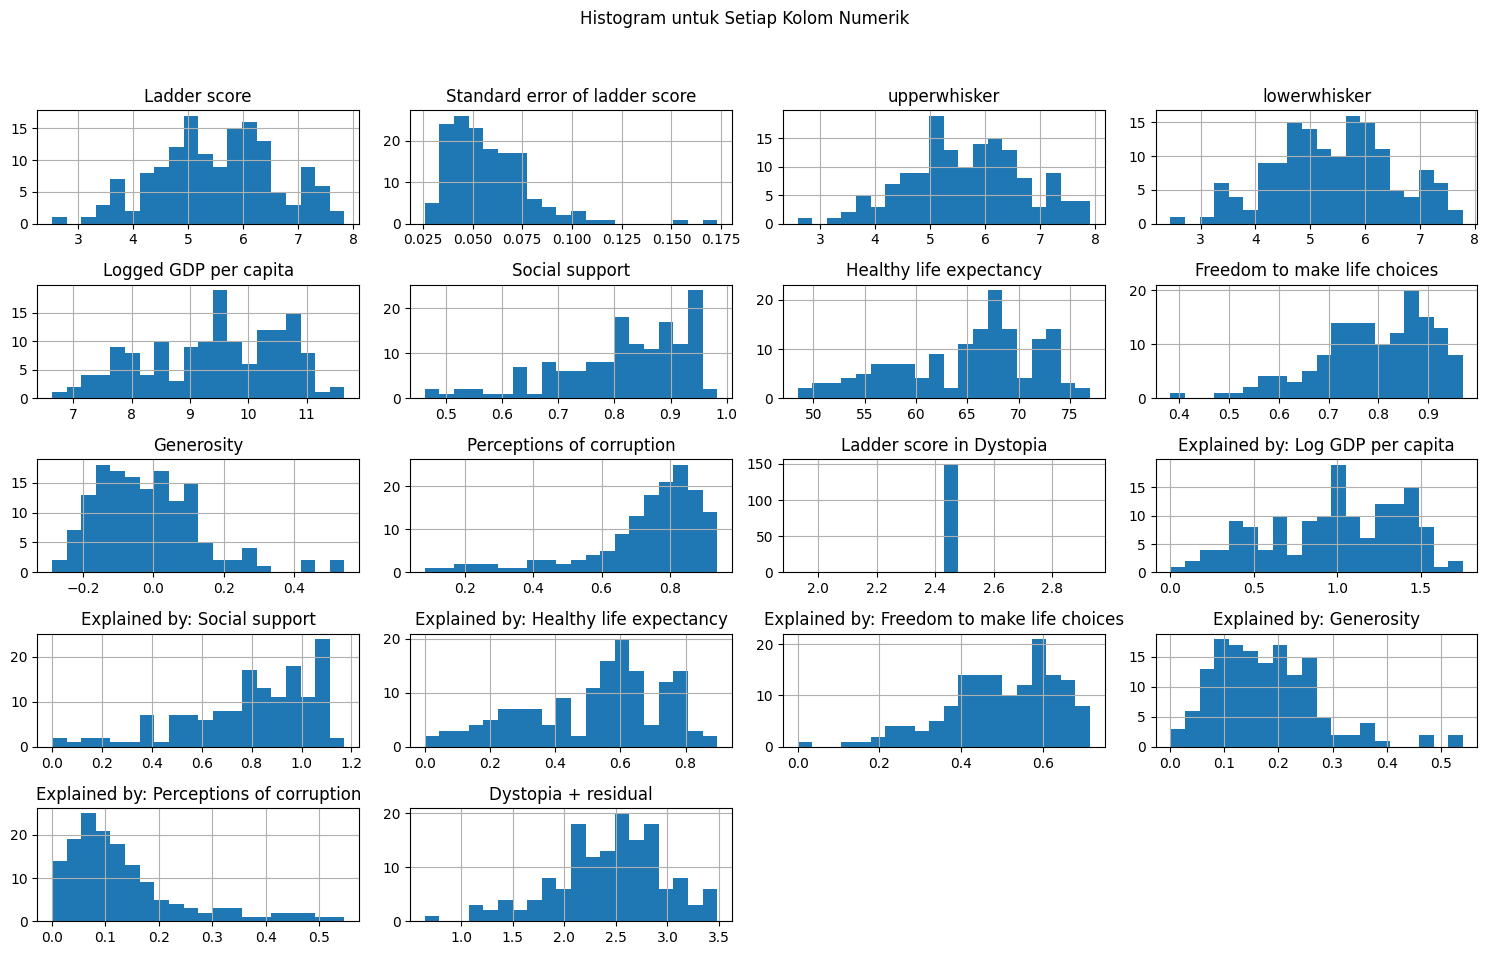


--- Menampilkan Matriks Korelasi ---


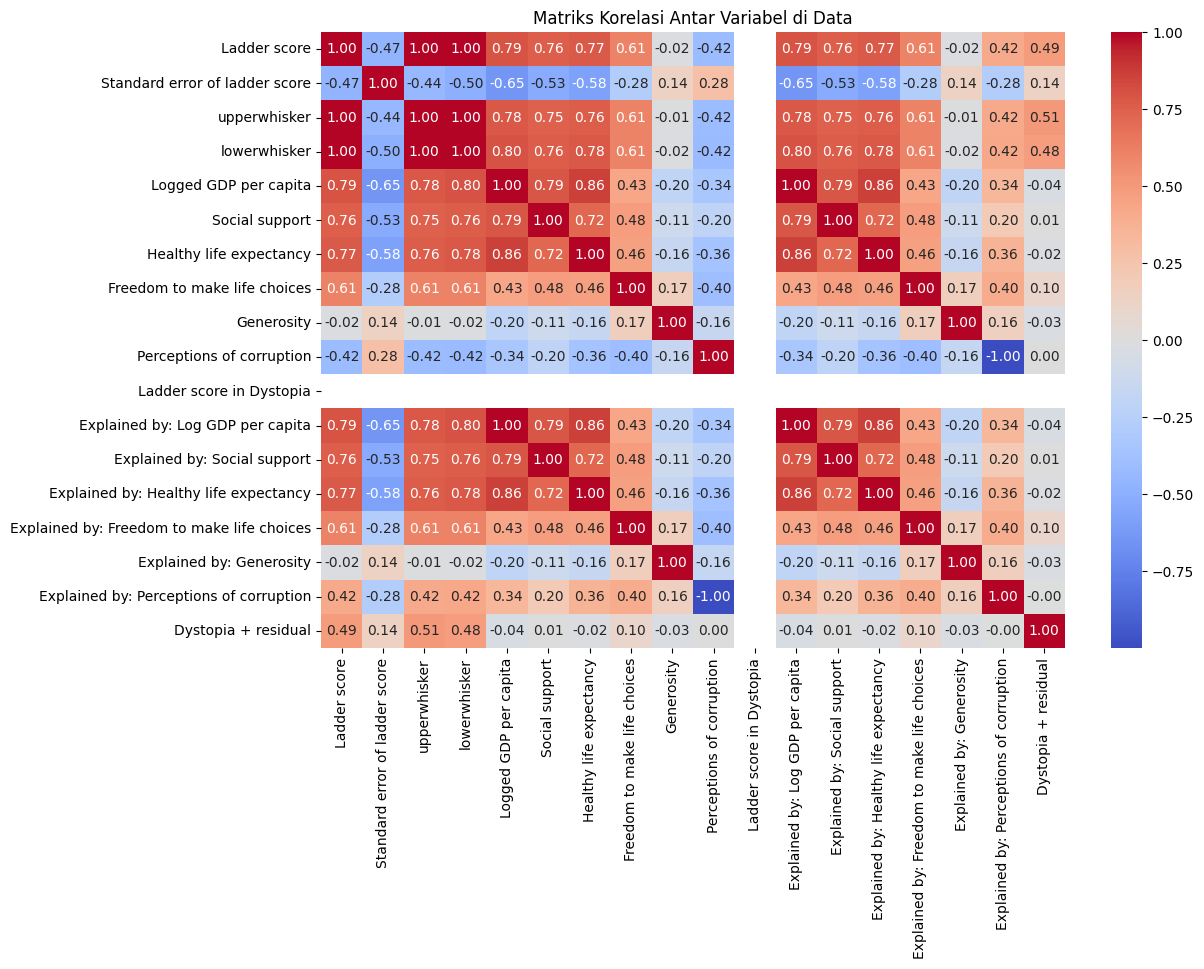

In [13]:
# Menampilkan info DataFrame (tipe data dan non-null count)
print("\n--- Info Data ---")
data.info()

# Menampilkan statistik deskriptif
print("\n--- Statistik Deskriptif ---")
print(data.describe())

# Membuat Histogram
print("\n--- Menampilkan Histogram ---")
data.hist(bins=20, figsize=(15, 10))
plt.suptitle("Histogram untuk Setiap Kolom Numerik")
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Agar suptitle tidak tumpang tindih
plt.show()

# Membuat Matriks Korelasi
print("\n--- Menampilkan Matriks Korelasi ---")
# Pilih hanya kolom numerik
numerical_columns = data.select_dtypes(include=['number']).columns
correlation_matrix = data[numerical_columns].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriks Korelasi Antar Variabel di Data")
plt.show()

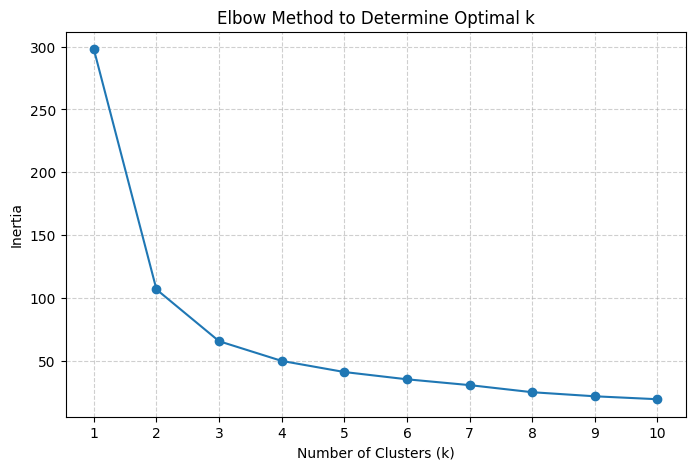

In [14]:
# 1. Memilih data untuk clustering
data_cluster = data[['Logged GDP per capita', 'Social support']].copy()

# 2. Scaling data
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_cluster)

# 3. Menjalankan loop untuk Elbow Method
inertia = []
range_k = range(1, 11) # Mencoba k dari 1 sampai 10

for k in range_k:
    # n_init=10 untuk menghilangkan warning FutureWarning di Colab
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(data_scaled)
    inertia.append(kmeans.inertia_)

# 4. Plotting Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(range_k, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method to Determine Optimal k')
plt.xticks(range_k) # Agar label sumbu X jelas 1, 2, 3, ... 10
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Data dengan hasil cluster (k=3):
   Logged GDP per capita  Social support  Cluster
0                 10.775           0.954        0
1                 10.933           0.954        0
2                 11.117           0.942        0
3                 10.878           0.983        0
4                 10.932           0.942        0

--- Menampilkan Visualisasi Cluster ---


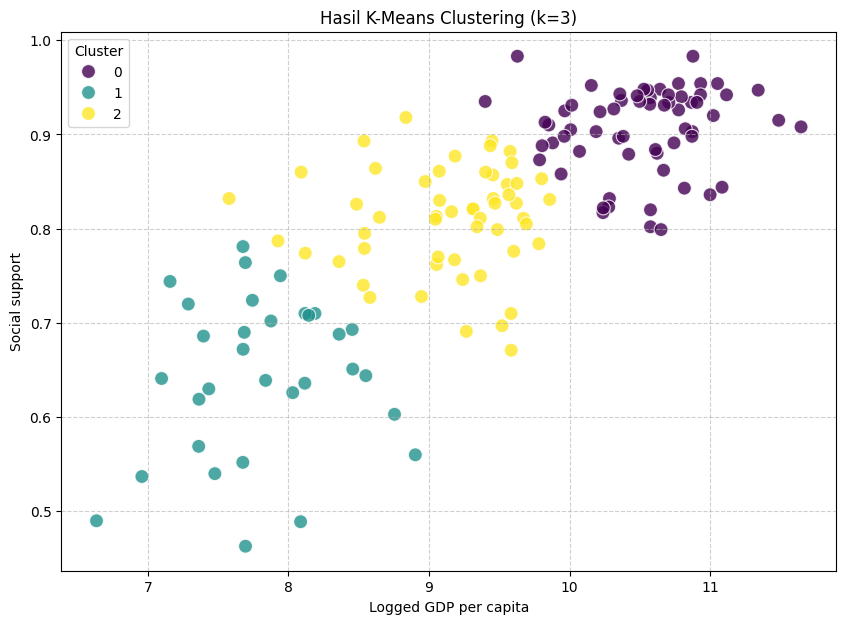

In [15]:
# 1. Menjalankan K-Means dengan k=3
# (Kita asumsikan k=3 adalah hasil optimal dari plot Elbow)
k_optimal = 3
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)

# 'data_scaled'
# Kita fit_predict() untuk mendapatkan label cluster
cluster_labels = kmeans.fit_predict(data_scaled)

# Tambahkan hasil cluster kembali ke DataFrame 'data_cluster'
# (yang berisi data asli, bukan yang di-scaling)
data_cluster['Cluster'] = cluster_labels

print(f"Data dengan hasil cluster (k={k_optimal}):")
print(data_cluster.head())

# 2. Visualisasi hasil clustering
print("\n--- Menampilkan Visualisasi Cluster ---")
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=data_cluster,
    x='Logged GDP per capita',
    y='Social support',
    hue='Cluster',       # Warnai titik berdasarkan kolom 'Cluster'
    palette='viridis',
    s=100,               # Ukuran titik
    alpha=0.8
)
plt.title(f'Hasil K-Means Clustering (k={k_optimal})')
plt.xlabel('Logged GDP per capita')
plt.ylabel('Social support')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()